# Технологии ИИ. Лабораторная работа №3
*Выполнил студент группы 6231 Демченко Максим*

# Генерация текстового описания к изображению
Всестороннее понимание зрения и языка и их взаимосвязей имеет решающее значение для понимания основных сходств и различий между этими модальностями и для изучения более обобщенных, значимых представлений. Автоматическая генерация описаний к изображениям может помогать исследователям в разметке данных, сокращать трудозатраты к описанию больших наборов изображений в каталогах и т.д.

## Постановка задачи 
На вход подается изображение, содержащее некую смысловую нагрузку. На выходе получается описание на естественном языке исходного изображения.

**Вход**: Изображение низкого разрешения в формате *.png*, *.bmp*, *.jpg*

**Выход**: Текстовое описание исходного изображения на естественном языке.
 
 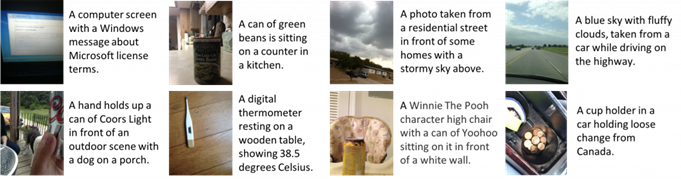

Рисунок 1. Пример изображений и их описаний.

## Пример набора данных
• https://vizwiz.org/tasks-and-datasets/image-captioning/

• https://storage.googleapis.com/openimages/web/index.html

## Предлагаемые архитектуры
• https://arxiv.org/abs/2112.04928

---
### Источники
"ПРАКТИКУМ
ПО КУРСУ «ТЕХНОЛОГИИ ИСКУССТВЕННОГО ИНТЕЛЛЕКТА И НЕЙРОСЕТЕВОЙ АНАЛИЗ ДАННЫХ»", авторы: Н.С. Давыдов, А.В. Никоноров

## 1. Библиотеки и параметры

In [1]:
from pathlib import Path
import io, json, textwrap, urllib.request, zipfile

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

Устройство: cuda


## 2. Изображение

Размер: (2000, 924) | режим: RGB


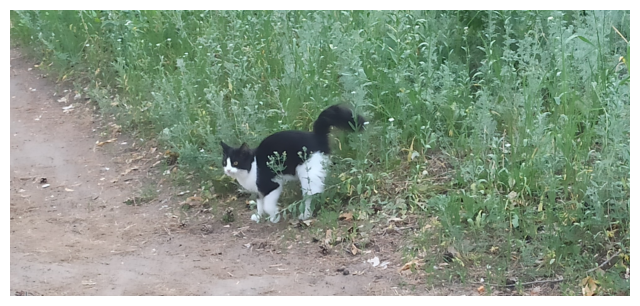

In [2]:
img = Image.open(Path('photos') / 'cat.jpg').convert('RGB')
print('Размер:', img.size, '| режим:', img.mode)

plt.figure(figsize=(8, 4))
plt.imshow(img)
plt.axis('off')
plt.show()

## 3. Данные

Берем набор VizWiz: фотографии, сделанные слепыми людьми, и по 5 подписей к каждой. Аннотации скачиваем целиком (4.5 МБ). Картинки val лежат в архиве на 3.5 ГБ, поэтому читаем из него по частям только первые 200 фотографий.

In [3]:
VIZ = Path('data/vizwiz'); VIZ.mkdir(parents=True, exist_ok=True)
ann_zip = VIZ / 'annotations.zip'
if not ann_zip.exists():
    urllib.request.urlretrieve('https://vizwiz.cs.colorado.edu/VizWiz_final/caption/annotations.zip', ann_zip)
with zipfile.ZipFile(ann_zip) as z:
    val = json.loads(z.read('annotations/val.json'))

images = {im['id']: im['file_name'] for im in val['images']}
caps = {}
for a in val['annotations']:
    if not a.get('is_rejected'):
        caps.setdefault(a['image_id'], []).append(a['caption'].strip())
print('Фотографий в val:', len(images), '| подписей:', sum(len(v) for v in caps.values()),
      '| подписей на фото: %.1f' % np.mean([len(v) for v in caps.values()]))

Фотографий в val: 7750 | подписей: 37786 | подписей на фото: 4.9


In [4]:
class HttpFile(io.RawIOBase):
    # файл на сервере: читаем только нужные куски (Range), чтобы не скачивать весь архив
    def __init__(self, url, block=1 << 20):
        self.url, self.block, self.pos = url, block, 0
        self.size = int(urllib.request.urlopen(urllib.request.Request(url, method='HEAD')).headers['Content-Length'])
        self.buf, self.buf_start = b'', 0
    def seekable(self): return True
    def readable(self): return True
    def tell(self): return self.pos
    def seek(self, offset, whence=0):
        self.pos = offset if whence == 0 else self.pos + offset if whence == 1 else self.size + offset
        return self.pos
    def read(self, n=-1):
        n = self.size - self.pos if n < 0 else min(n, self.size - self.pos)
        if not (self.buf_start <= self.pos and self.pos + n <= self.buf_start + len(self.buf)):
            end = min(self.pos + max(n, self.block), self.size) - 1
            req = urllib.request.Request(self.url, headers={'Range': f'bytes={self.pos}-{end}'})
            self.buf, self.buf_start = urllib.request.urlopen(req).read(), self.pos
        i = self.pos - self.buf_start
        self.pos += n
        return self.buf[i:i + n]

N_IMAGES = 200
IMG_DIR = VIZ / 'images'; IMG_DIR.mkdir(exist_ok=True)
ids = sorted(images)[:N_IMAGES]
missing = [i for i in ids if not (IMG_DIR / images[i]).exists()]
if missing:
    z = zipfile.ZipFile(HttpFile('https://vizwiz.cs.colorado.edu/VizWiz_final/images/val.zip'))
    for i in missing:
        (IMG_DIR / images[i]).write_bytes(z.read('val/' + images[i]))
print('Картинок на диске:', len(list(IMG_DIR.glob('*.jpg'))))

Картинок на диске: 200


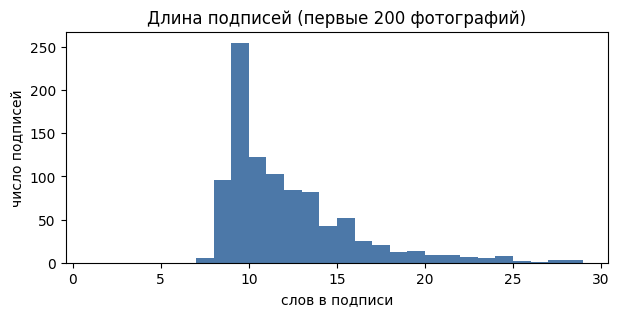

Средняя длина подписи: 11.8 слов


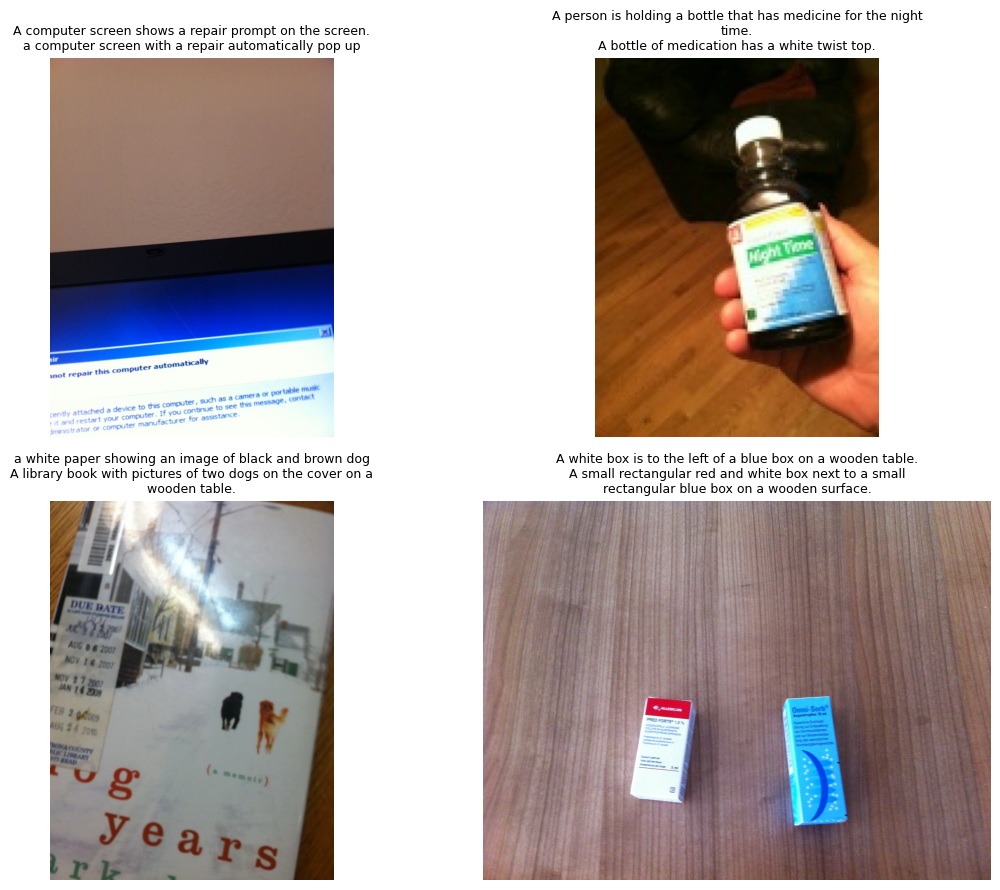

In [5]:
lens = [len(c.split()) for i in ids for c in caps[i]]
plt.figure(figsize=(7, 3))
plt.hist(lens, bins=range(1, 30), color='#4C78A8')
plt.xlabel('слов в подписи'); plt.ylabel('число подписей'); plt.title('Длина подписей (первые 200 фотографий)')
plt.show()
print('Средняя длина подписи: %.1f слов' % np.mean(lens))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, i in zip(axes.ravel(), ids[:4]):
    ax.imshow(Image.open(IMG_DIR / images[i]).convert('RGB')); ax.axis('off')
    ax.set_title('\n'.join(textwrap.fill(c, 60) for c in caps[i][:2]), fontsize=9)
plt.tight_layout(); plt.show()

## 4. Модель

Готовая модель BLIP (`Salesforce/blip-image-captioning-base`, 224 млн параметров) из библиотеки `transformers`.

In [6]:
from transformers import BlipProcessor, BlipForConditionalGeneration

MODEL = 'Salesforce/blip-image-captioning-base'
processor = BlipProcessor.from_pretrained(MODEL)
model = BlipForConditionalGeneration.from_pretrained(MODEL).to(device).eval()

@torch.no_grad()
def caption(image):
    inputs = processor(images=image, return_tensors='pt').to(device)
    out = model.generate(**inputs, max_new_tokens=30, num_beams=3)
    return processor.decode(out[0], skip_special_tokens=True)

print('Подпись к моему фото:', caption(img))

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 473/473 [00:00<00:00, 27037.16it/s]

Подпись к моему фото: a black and white cat walking down a dirt road


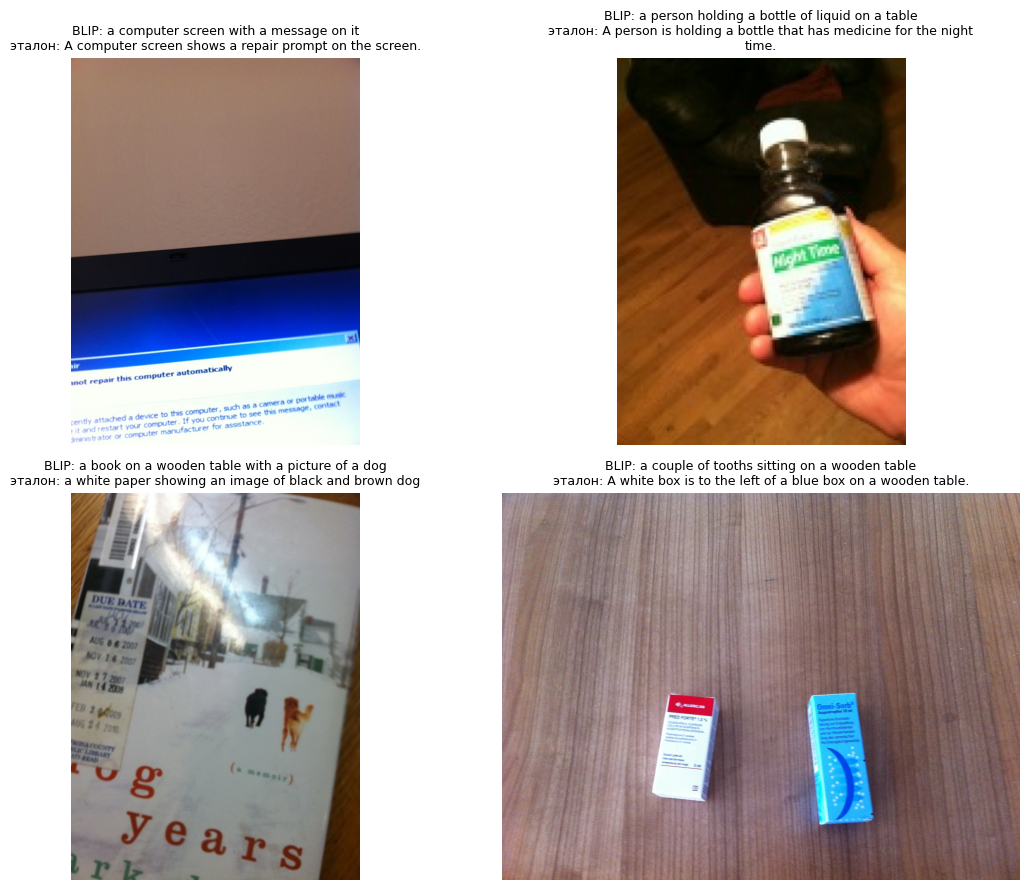

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, i in zip(axes.ravel(), ids[:4]):
    im = Image.open(IMG_DIR / images[i]).convert('RGB')
    ax.imshow(im); ax.axis('off')
    ax.set_title('BLIP: ' + caption(im) + '\nэталон: ' + textwrap.fill(caps[i][0], 60), fontsize=9)
plt.tight_layout(); plt.show()